# Platt calibration

This notebook calibrates the predicted probabilities of all trained models and compares them before and after calibration.
Calibration is fitted on the calibration split for every model saved in `models/`; calibrated models go to `model_calibrated/` and metrics to `results/platt/`.

The functions used are documented in `src/calibration_utils.py`.

In [5]:
import matplotlib.pyplot as plt
import pandas as pd

from src.calibration_utils import calibrate_all_models, plot_all_calibration_comparison

In [6]:
# =============================================================================
# CELL 1: LOAD DATA
# =============================================================================


# Configuration
DATA_PATH = 'data/processed_data_imputed.xlsx'
COLS_TO_DROP = ['patient_ids', 'feat_40', 'feat_82']

# Load the three splits
print("Loading data...")

cal_data = pd.read_excel(DATA_PATH, sheet_name='calibration')
test_data = pd.read_excel(DATA_PATH, sheet_name='test')

# Split features / target
X_cal = cal_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_cal = cal_data.iloc[:, -1]

X_test = test_data.iloc[:, :-1].drop(columns=COLS_TO_DROP, errors='ignore')
y_test = test_data.iloc[:, -1]

print("Data loaded:")
print(f"   - Calibration: {X_cal.shape[0]} lignes, {X_cal.shape[1]} features")
print(f"   - Test: {X_test.shape[0]} lignes, {X_test.shape[1]} features")

Loading data...
Data loaded:
   - Calibration: 56725 lignes, 81 features
   - Test: 56938 lignes, 81 features


In [7]:
# =============================================================================
# CELL 2: CALIBRATE ALL MODELS (PLATT)
# =============================================================================


# Calibrate every saved model with Platt scaling
results_df = calibrate_all_models(
    model_dir='models',
    output_dir='model_calibrated',
    X_cal=X_cal,
    y_cal=y_cal,
    X_test=X_test,
    y_test=y_test,
    method='sigmoid',  # Platt Scaling
    pattern='*_tuned.pkl',
    save_plots=True,
    plot_dir='model_calibrated/plots',
    save_results_dir='results/platt'
)

print("\nCalibration finished.")

Models found in 'models':
   - logistic_regression_tuned.pkl
   - gradient_boosting_tuned.pkl
   - random_forest_tuned.pkl
   - xgboost_tuned.pkl

CALIBRATING 4 MODELS
   Method: sigmoid (Platt scaling)
   Calibration data: 56725 samples
   Test data: 56938 samples

──────────────────────────────────────────────────
Model: logistic_regression
──────────────────────────────────────────────────
   ✓ Model loaded: models/logistic_regression_tuned.pkl
   Calibrating with method: sigmoid

   Test set metrics:
      Brier Score:   0.1928 → 0.1932 (↑ 0.0004)
      Log Loss:      0.5679 → 0.5689 (↑ 0.0010)
      ROC-AUC:       0.7761 → 0.7761
   ✓ Plot saved: results/platt/logistic_regression_calibrated/logistic_regression_calibration_curve.png
   ✓ Metrics saved: results/platt/logistic_regression_calibrated/logistic_regression_calibrated_metrics.csv
   ✓ Results saved: results/platt/logistic_regression_calibrated/logistic_regression_calibrated_results.txt
   ✓ Calibrated model saved: model_ca

✓ Comparison saved: model_calibrated/comparison_calibration.png


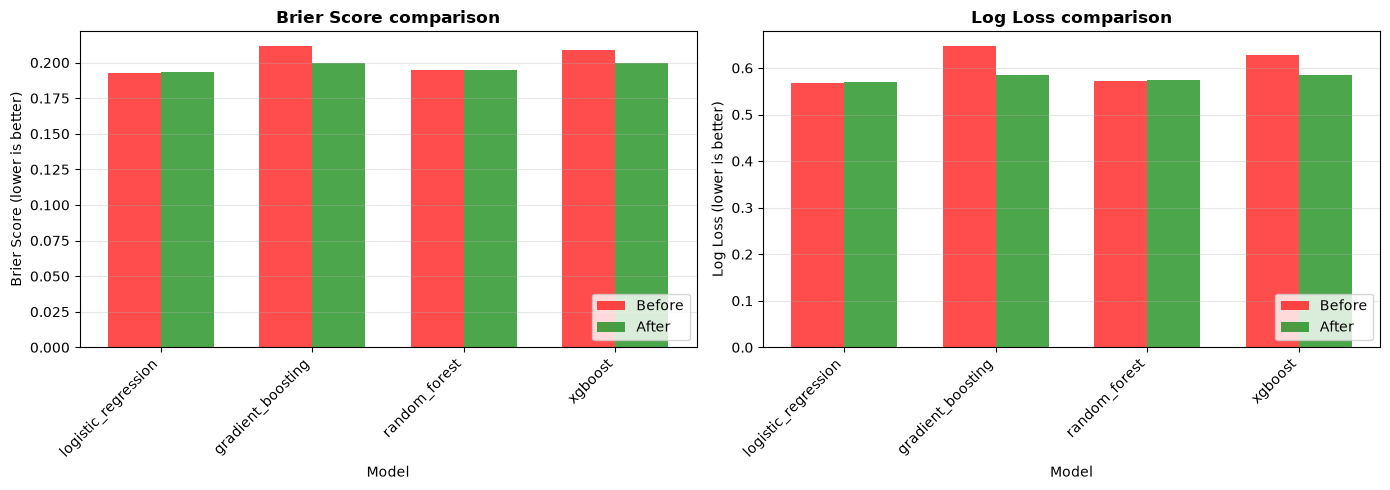


Summary table:
              model  brier_before  brier_after  log_loss_before  log_loss_after  roc_auc_before  roc_auc_after  brier_improvement  log_loss_improvement
logistic_regression      0.192844     0.193233         0.567907        0.568904        0.776075       0.776075          -0.000389             -0.000997
  gradient_boosting      0.211388     0.199589         0.646383        0.585179        0.759809       0.759809           0.011799              0.061205
      random_forest      0.194846     0.195139         0.572585        0.573505        0.769605       0.769605          -0.000293             -0.000920
            xgboost      0.208874     0.200027         0.627587        0.585795        0.760861       0.760861           0.008847              0.041792


In [8]:
# =============================================================================
# CELL 3: COMPARISON PLOTS
# =============================================================================
# Compare all models
fig = plot_all_calibration_comparison(
    results_df, 
    save_path='model_calibrated/comparison_calibration.png'
)
plt.show()

# Summary table
print("\nSummary table:")
print(results_df.to_string(index=False))

## Conclusion

Platt scaling only helps the two boosting models, which were the most miscalibrated: log loss drops from 0.646 to 0.585 for gradient boosting (−9.5%) and from 0.628 to 0.586 for XGBoost (−6.7%). Logistic regression and random forest were already well calibrated, and Platt scaling slightly worsens them (log loss +0.001). ROC-AUC is unchanged for every model, since Platt scaling is a monotonic transformation that preserves the ranking of pairs. Even after calibration, logistic regression remains the best model (log loss 0.569 against 0.585 for the best boosting model).